# Supplemental Figure 7, panel C

Scatter plots showing:
- association between eRNA production (PRO-seq counts) and H3K27ac levels at enhancers (unstimulated conditions)
- correlation between change in accessibility and change in PRO-seq at cREs in response to IFN-gamma

*Output: PanelC.pdf*

# Setup

In [1]:
library(tidyverse)
library(rtracklayer)
library(here)
library(ggpointdensity)
library(patchwork)
library(ggrastr)
here::i_am("figures/SuppFig7/PanelC/PanelC_scatter.ipynb")
sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: GenomicRanges

Loading required package: stats4

Loading required package: BiocGenerics


Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:lubridate’:

    intersect, setdiff, union


The following objects are masked from ‘package:dplyr’:

    combine, intersect, setdiff, union


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:b

R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] ggrastr_1.0.2        patchwork_1.3.0      ggpointdensity_0.2.1
 [4] here_1.0.2           rtracklayer_1.58.0   GenomicRanges_1.50.2
 [7] GenomeInfoDb_1.34.9  IRanges_2.32.0       S4Vectors_0.36.2    
[10] BiocGenerics_0.44.0  lubridate_1.9.4      forcats_1.0.0       
[13] str

# load data

In [3]:
ifn_PRO <- read.delim(
    here("inputs","countmat","PROseq_eRNA","IFN_v_Veh_PROseq_cRE.tsv"), sep='\t')

ifn_PRO_counts <- read.delim(
    here("inputs","countmat","PROseq_eRNA","PROseq_cRE_counts.tsv"), sep='\t')
ifn_cpm <- apply(ifn_PRO_counts[,-1:-5], 2, function(x) 1000000*x/sum(x)) %>%
                 data.frame() %>%
                 +1 %>%
                 log2()

ifn_ATAC <- read.delim(
    here("inputs","DARs","GM12878_stimulus","DAR_IFN_1h.tsv"), sep='\t')

H3K27ac <- read.delim(
    here("inputs","bigwig","ENCODE","GM12878","other","H3K27ac.tab"), sep='\t', header=F) %>% arrange(V1)

# generate object for plotting

In [4]:
dat <- data.frame(
        PRO_lfc=ifn_PRO$log2FoldChange,
        PRO_change=ifn_PRO$change,
        ATAC_lfc=ifn_ATAC$logFC, 
        ATAC_change=ifn_ATAC$change,
        H3K27ac=log2(H3K27ac$V6+1),
        PRO_counts=rowMeans(ifn_cpm[,grep("veh_veh", colnames(ifn_cpm))]),
        type=ifn_PRO$type) %>%
        filter(grepl("enh", type))

# plot PRO-seq counts vs H3K27ac

,p,r
,<dbl>,<dbl>
cor,0,0.6319967


geom_pointdensity() using method='kde2d' due to large number of points (>20k). You may override this by setting method='neighbors'.

`geom_smooth()` using formula = 'y ~ x'


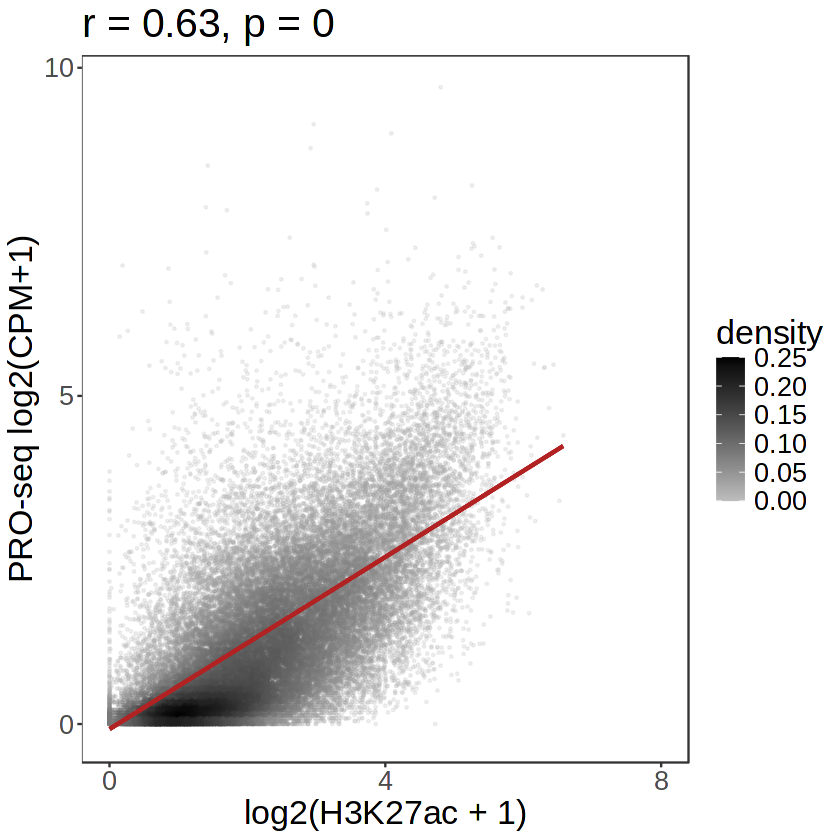

In [117]:
# stats (Pearson's r and p-value)
stats <- data.frame(
            p=cor.test(dat$H3K27ac, dat$PRO_counts)$p.value,
            r=cor.test(dat$H3K27ac,dat$PRO_counts)$estimate)
stats

# ggplot object
plot1 <- ggplot(data=dat %>% filter(grepl("enh", type)),
       aes(x=H3K27ac, y=PRO_counts)) + 
    rasterize(geom_pointdensity(size=.5, alpha=.2), dpi=300) +
    rasterize(geom_smooth(method=lm, color="firebrick"), dpi=300) +
    scale_color_gradient2(low  = "#BDBDBD",mid="#BDBDBD", high = "black", limits=c(0,0.25)) +
    theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=20)) +
    xlab("log2(H3K27ac + 1)") +
    ylab("PRO-seq log2(CPM+1)") +
    scale_x_continuous(limits=c(0,8),breaks=c(0,4,8)) +
    scale_y_continuous(breaks=c(0,5,10)) +
    scale_fill_gradient2(low="#BDBDBD", mid="#BDBDBD", high="black") +
    ggtitle(paste0("r = ", format(stats$r, digits=2), ", p = ", format(stats$p, digits=2)))
plot1

# plot ∆ PRO-seq vs ∆ATAC in response to IFN-g

,p,r
,<dbl>,<dbl>
cor,0,0.227335


`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 596 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 596 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 4 rows containing missing values or values outside the scale range
(`geom_point()`).”


       
        FALSE  TRUE
  FALSE 34505   280
  TRUE    182    78

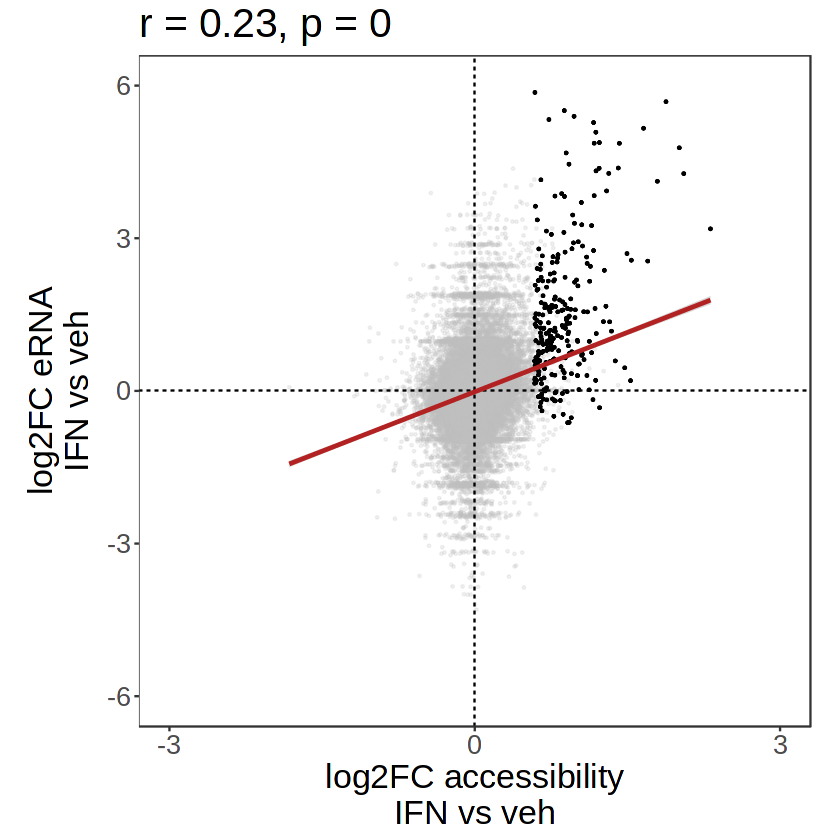

In [125]:
# stats (Pearson's r and p-val, as above)
stats2 <- data.frame(
            p=cor.test(dat$PRO_lfc, dat$ATAC_lfc)$p.value,
            r=cor.test(dat$PRO_lfc,dat$ATAC_lfc)$estimate)
stats2

plot2 <- ggplot(data=dat,
       aes(x=ATAC_lfc, y=PRO_lfc)) + 
    rasterize(geom_point(size=.5, alpha=.2, color="grey"), dpi=300) +
    rasterize(geom_point(data=dat %>% filter(ATAC_change=="up"), size=.5, color="black"), dpi=300) + 
    geom_hline(yintercept=0,linetype=2) +
    geom_vline(xintercept=0,linetype=2) +
    geom_smooth(method=lm, color="firebrick") +
    theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=20)) +
    xlab("log2FC accessibility\nIFN vs veh") +
    ylab("log2FC eRNA\nIFN vs veh") +
    scale_x_continuous(limits=c(-3,3), breaks=c(-3,0,3)) +
    scale_y_continuous(limits=c(-6,6)) +
    ggtitle(paste0("r = ", format(stats2$r, digits=2), ", p = ", format(stats2$p, digits=2))) +
    coord_fixed(ratio=.5)
plot2



# Compile plots

geom_pointdensity() using method='kde2d' due to large number of points (>20k). You may override this by setting method='neighbors'.

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 596 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 596 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 4 rows containing missing values or values outside the scale range
(`geom_point()`).”
geom_pointdensity() using method='kde2d' due to large number of points (>20k). You may override this by setting method='neighbors'.

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 596 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 596 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 4 rows

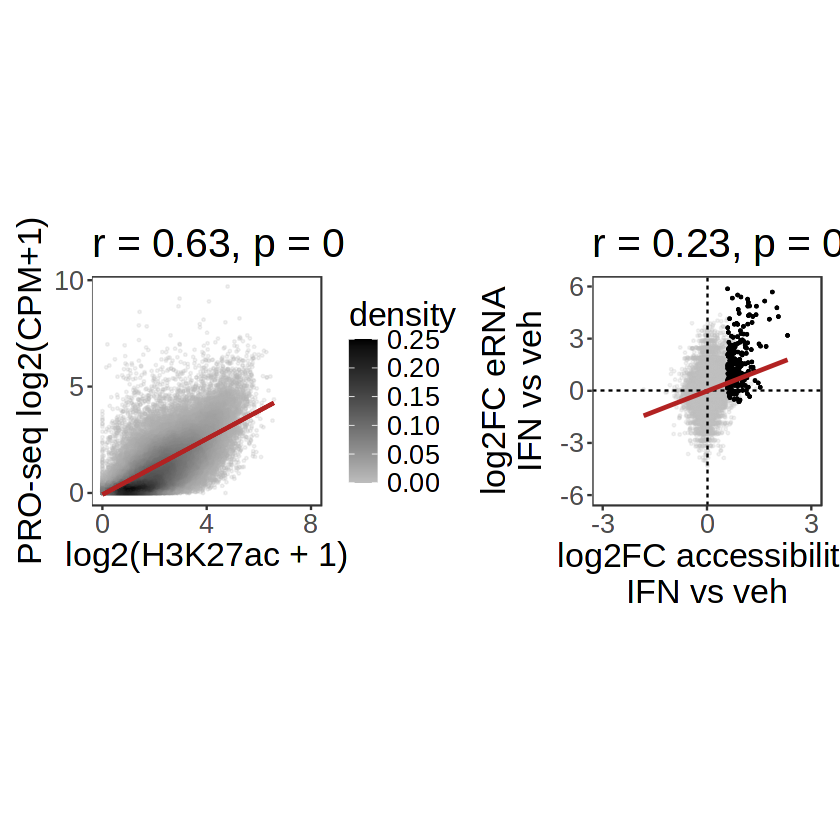

In [124]:
(plot1 | plot2) 
ggsave("PanelC.pdf", width=8, height=8)

# enrichment test for overlap between gained-ATAC and gained-PRO seq cRES

In [1]:
data.frame(
        PRO_change=ifn_PRO$change=="up",
        ATAC_change=ifn_ATAC$change=="up") %>%
    table() %>%
    fisher.test() 

ERROR: Error in data.frame(PRO_change = ifn_PRO$change == "up", ATAC_change = ifn_ATAC$change == : could not find function "%>%"
